# Figure 7 -- motor neuron firing by condition (spike-raster version)
`[F7R-DOC]` One row per motor neuron (A2, A4, F1), one column per condition:

1. steady hold in the **low-force** target
2. steady hold in the **high-force** target
3. **movement into** the high-force target (as_off trials)

Each panel is the probe position (target band shaded) over the spike rate (0-120 Hz, spike ticks along the top). Bottom row: one stable-period (REST) position-vs-rate crunch per neuron, as in the A2 panels D/E.

The work lives in `figure7_raster.py`. Records are cached as parquet in `data_cache/figure7_raster/`, so after the first build the notebook runs in seconds. Figures go to `./Figure7_raster/`.

In [6]:
# [F7R-SETUP]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mapd import Sinq
import figure7_raster as f7r

%matplotlib widget
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
# [F7R-CELLS]
# Row label -> (cell, last trial to use). None = all trials.
#   A2: 210915_F1_C1, the HIGHLIGHT cell of the A2 notebook
#   A4: 241203_F2_C1, the A4 notebook's recruited-A4 example (trial 242);
#       241115_F1_C1, the A4 notebook's main example cell, is the alternative
#   F1: 210331_F2_C1 has spike detection on every trial. 210319_F2_C1 is the
#       alternative (its voltage was corrected long ago) but spike detection
#       has never been run on it; once it has, swap it in with trial_max=200,
#       where the recording is best.
CELLS = {
    'A2': ('210915_F1_C1', None),
    'A4': ('241203_F2_C1', None),
    # 'A4': ('241115_F1_C1', None),
    'F1': ('210331_F2_C1', None),
    # 'F1': ('210319_F2_C1', None),   # spikes detected 2026-11-01; all trials OK
}
# F1 rarely fires, so its rate trace is mostly flat: True draws the raw
# membrane potential (spikes in, resampled to 5 kHz) in place of the rate.
F1_SHOW_VM = True
VM_CELLS = ['F1'] if F1_SHOW_VM else []
sinq = Sinq(sinqname='dataset_4_mns')

Found data directory: D:\Data


`[F7R-LOAD-DOC]` Load each cell's records and per-trial metadata, from the cache when it exists (`recompute=True` rebuilds). Then re-classify at the cell's own p90 `v_rest` (the A4-VREST rule; it never goes below the default, so a clean cell is unchanged) and collect the stable bouts for the crunch: REST bouts of 1 s or longer on task trials, with the cue + 200 ms, the current step and the 0.5 s pre-movement run-up removed. Exact spike times are read from the trial files once and cached too (`{cell}_spikes.parquet`); the raster ticks use them.

In [8]:
# [F7R-LOAD]
data, rows = {}, []
for lab, (cid, trial_max) in CELLS.items():
    rec, meta = f7r.load_cell(sinq, cid, recompute=False)
    rec, meta = f7r.restrict_trials(rec, meta, trial_max)
    rec, v_rest = f7r.apply_p90_v_rest(rec)
    frames, bouts = f7r.stable_bouts(rec, meta)
    spikes = f7r.load_spike_times(sinq, cid, sorted(rec['trial'].unique()))
    data[lab] = {'cell_id': cid, 'rec': rec, 'meta': meta,
                 'frames': frames, 'bouts': bouts, 'v_rest': v_rest,
                 'spikes': spikes, 'protocol': f7r.cell_protocol(sinq, cid)}
    rows.append({'row': lab, 'cell': cid, 'trials': rec['trial'].nunique(),
                 'v_rest': v_rest, 'stable_bouts': len(bouts),
                 'stable_s': round(bouts['dur_s'].sum(), 1) if len(bouts) else 0,
                 'lo_trials': int((meta['pyasState'] == 'lo').sum()),
                 'hi_trials': int((meta['pyasState'] == 'hi').sum()),
                 'hi_as_off': int(((meta['pyasState'] == 'hi')
                                   & (meta['as_outcome'] == 'as_off')).sum())})
pd.DataFrame(rows).set_index('row')

210915_F1_C1: reading cached records (data_cache\figure7_raster\210915_F1_C1_records.parquet)
241115_F1_C1: reading cached records (data_cache\figure7_raster\241115_F1_C1_records.parquet)
210331_F2_C1: reading cached records (data_cache\figure7_raster\210331_F2_C1_records.parquet)


,cell,trials,v_rest,stable_bouts,stable_s,lo_trials,hi_trials,hi_as_off
row,,,,,,,,
A2,210915_F1_C1,350,30.0,503,2419.8,208,142,15
A4,241115_F1_C1,620,30.0,761,3861.7,284,336,131
F1,210331_F2_C1,768,31.0,1279,2909.4,400,368,105


`[F7R-CANDS-DOC]` Candidate windows for every (cell, condition):
- **holds**: REST runs of 3 s or longer with at least 95% of frames inside the trial's target band (+/-5 px), ranked longest and then stillest
- **movement**: the first entry into the high-force target from below on as_off trials, with MOVE in the 0.5 s before entry and a rise of at least 20 px, shown from 2 s before to 2 s after entry and ranked by rise

The row number in each table is what `[F7R-BROWSE]` prints over the thumbnails.

In [ ]:
# [F7R-CANDS]
cands = {lab: f7r.find_candidates(d['rec'], d['meta']) for lab, d in data.items()}
pd.DataFrame({lab: {cond: len(c) for cond, c in cc.items()}
              for lab, cc in cands.items()})

# 	A2	A4	F1
# lo_hold	91	276	143
# hi_hold	67	80	34
# hi_move	9	97	85


,A2,A4,F1
lo_hold,91,276,143
hi_hold,67,80,34
hi_move,9,97,85


,trial,t0,t1,dur_s,x_mean,x_ptp,rate_mean,rate_sd,n_spikes,as_outcome
0,370,-0.30,10.27,10.58,171.31,2.50,25.61,3.15,271,no_as_no_mv
1,70,-0.30,8.03,8.34,171.09,2.19,26.87,3.79,224,no_as_no_mv
2,72,-0.30,6.37,6.68,162.86,0.94,26.55,3.84,178,no_as_no_mv
3,300,-0.30,6.37,6.68,175.16,1.25,25.18,3.97,168,no_as_no_mv
4,271,-0.30,6.35,6.66,146.16,1.25,27.16,4.55,181,no_as_no_mv
5,82,-0.30,6.33,6.63,157.76,0.94,24.75,3.13,164,no_as_no_mv
6,290,-0.30,6.32,6.63,179.59,0.62,28.81,3.68,191,no_as_mv
7,59,21.84,28.46,6.63,158.44,8.75,39.15,3.98,259,no_as_mv
8,280,-0.30,6.27,6.58,147.87,0.94,22.62,3.87,149,no_as_no_mv
9,78,-0.30,6.27,6.58,158.60,0.94,23.99,3.41,158,no_as_no_mv


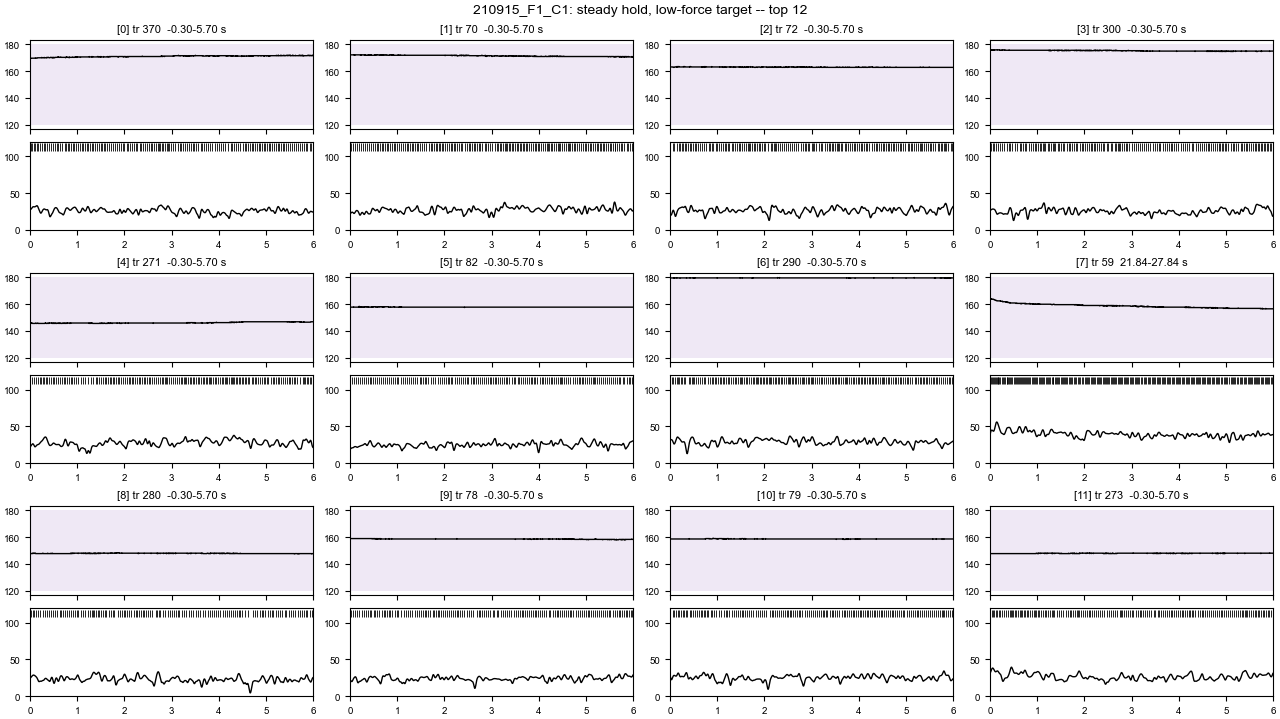

In [10]:
# [F7R-BROWSE]
# Thumbnails of the top candidates for one (cell, condition). Change and re-run.
# Each run also saves Figure7_raster/candidates_{cell}_{condition}.png.
LAB, COND = 'A2', 'lo_hold'          # COND in 'lo_hold', 'hi_hold', 'hi_move'
N_SHOW = 12

d = data[LAB]
display(cands[LAB][COND].head(N_SHOW).round(2))
f7r.plot_candidates(d['rec'], d['meta'], cands[LAB][COND], d['cell_id'], COND,
                    n=N_SHOW, spikes=d['spikes'],
                    vm_protocol=d['protocol'] if LAB in VM_CELLS else None);

In [11]:
# [F7R-EXAMPLES]
# The chosen windows: (trial, t0, t1) in trial time, s; the movement column
# adds t_entry, drawn as a dashed line. None leaves the panel blank.
# PROVISIONAL: these are the top-ranked candidate in each [F7R-CANDS] table,
# put in so the figure draws. Replace them as you choose from [F7R-BROWSE].
EXAMPLES = {
    ('A2', 'lo_hold'): (72, -0.30, 5.70),    # chosen 2026-11-01
    ('A2', 'hi_hold'): (225, -0.30, 5.70),   # chosen
    ('A2', 'hi_move'): (121, -0.40, 3.60, 1.60),   # chosen; also liked:
    #   (313, -0.29, 3.71, 1.71), (310, -1.04, 2.96, 0.96), (315, 0.03, 4.03, 2.03)
    # A4 = 241203_F2_C1
    ('A4', 'lo_hold'): (475, -0.30, 5.70),   # chosen 2026-11-01
    ('A4', 'hi_hold'): (364, -0.30, 5.70),   # chosen
    ('A4', 'hi_move'): (18, 0.91, 4.91, 2.91),   # chosen 2026-11-01
    # A4 = 241115_F1_C1, provisional:
    #   lo_hold (60, -0.30, 5.70), hi_hold (257, -0.30, 5.70),
    #   hi_move (593, -0.96, 3.04, 1.04)
    ('F1', 'lo_hold'): (243, -0.30, 5.70),   # chosen 2026-11-01
    ('F1', 'hi_hold'): (678, -0.06, 5.18),   # chosen; the whole 5.25 s hold
    ('F1', 'hi_move'): (256, -0.63, 3.37, 1.37),   # chosen
}
EXAMPLES = {k: v for k, v in EXAMPLES.items() if v is not None}

,n_bouts,slope_hz_per_px,r
A2,503.0,0.114,0.757
A4,761.0,0.023,0.372
F1,1279.0,0.000,0.047


saved C:\Users\tony\Code\FlyLearning\Figure7_raster\Figure7_MN_raster.svg
saved C:\Users\tony\Code\FlyLearning\Figure7_raster\Figure7_MN_raster.png


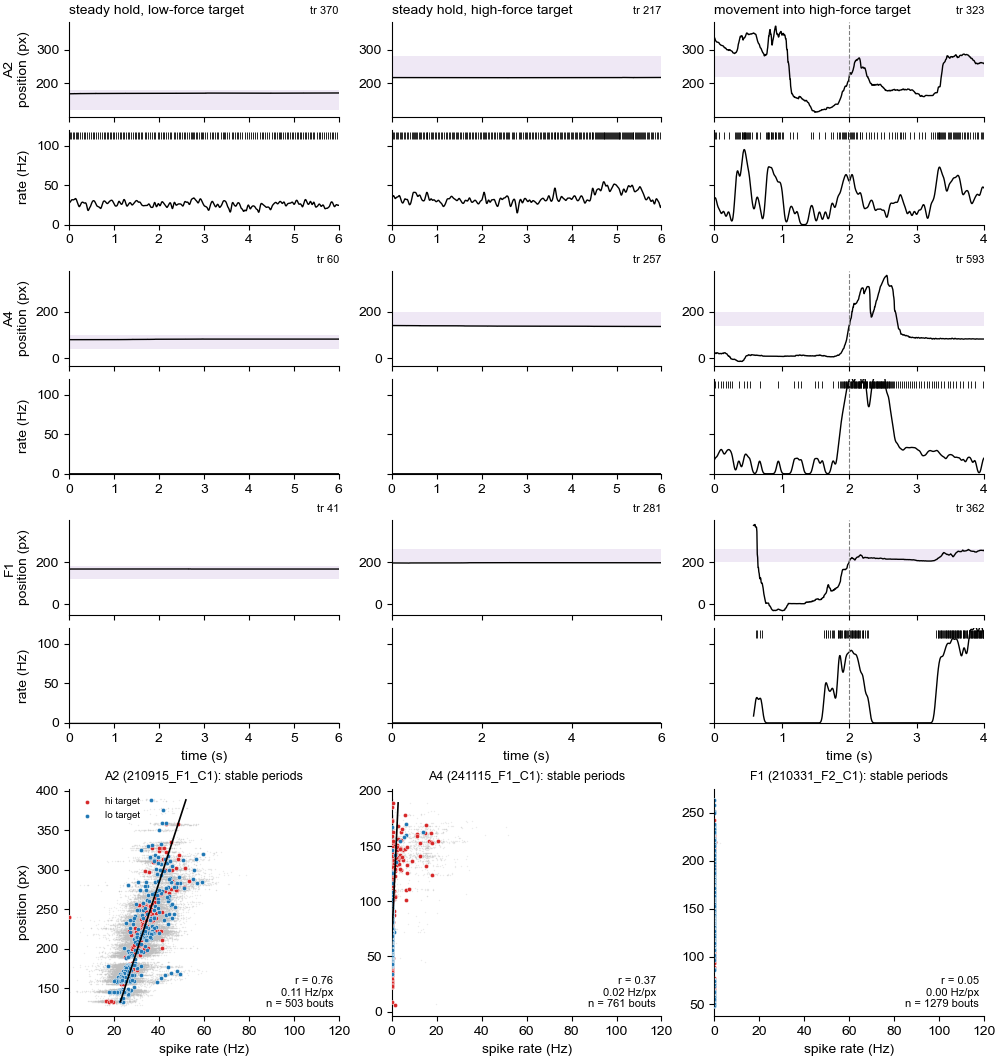

In [12]:
# [F7R-FIG]
fig, axes, crunch_stats = f7r.make_figure(data, EXAMPLES, list(CELLS),
                                         vm_cells=VM_CELLS)
display(pd.DataFrame(crunch_stats).T.round(3))
f7r.save_fig(fig, 'Figure7_MN_raster')

## Stable-period crunch: A4 and F1
`[F7R-CRUNCH-DOC]` The A2 panels D/E arrangement for the other neurons: one row per cell type, one panel per cell (frames grey, bout means coloured by target, fit of rate on position), and a last column overlaying every cell's bout means and fit. Rate axis 0-120 Hz everywhere; position shared within a row.

Add cells to `CRUNCH_GROUPS` as they come in (e.g. the proximal-EMG F1 recordings, once spikes are detected -- they will need `spike_field='EMGspikes'` when their records are built). Note 210917_F2_C1's probeZero is 29.5 px off the convention, so its absolute positions are not strictly comparable with the other cells.

In [ ]:
# [F7R-CRUNCH]
CRUNCH_GROUPS = {
    'A4': ['241115_F1_C1', '210917_F2_C1', '241203_F2_C1'],
    'F1': ['210331_F2_C1', '210319_F2_C1'],
}
crunch_data, crunch_rows = {}, []
for lab, cells in CRUNCH_GROUPS.items():
    for cid in cells:
        rec, meta = f7r.load_cell(sinq, cid)
        rec, v_rest = f7r.apply_p90_v_rest(rec)
        frames, bouts = f7r.stable_bouts(rec, meta)
        crunch_data[cid] = {'frames': frames, 'bouts': bouts}
        crunch_rows.append({'type': lab, 'cell': cid, 'trials': rec['trial'].nunique(),
                            'v_rest': v_rest, 'bouts': len(bouts),
                            'stable_s': round(bouts['dur_s'].sum()),
                            'frac_bouts_firing': round((bouts['rate'] >= 0.5).mean(), 3)})
display(pd.DataFrame(crunch_rows).set_index('cell'))
crunch_fig, crunch_stats = f7r.make_crunch_figure(CRUNCH_GROUPS, crunch_data)
display(crunch_stats.round(3))
f7r.save_fig(crunch_fig, 'Figure7_crunch_A4_F1')

## Next
`[F7R-NEXT]` Two follow-up analyses of spike rate during movement, to start once this figure is settled:
1. **A2 pre-move alignment.** Align A2 rate on movement onset. The rate rises briefly before the movement, then often dips, then rises again while the probe is still moving up.
2. **Movement bouts split by vigour.** Split the movement bouts by effort or speed (perhaps log deciles) and compare the mean spike-rate trajectories of strong and weak movements.